PARTICLE SWARM OPTIMIZATION FOR FINDING MINIMUM OF THREE=DIMENSIONAL QUADRATIC

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def objective_function(position):
    return np.sum(position ** 2)

In [ ]:
num_particles = 10
dimensions = 3
iterations = 50

w = 0.7
c1 = 1.5
c2 = 1.5

lower_bound = -10
upper_bound = 10

In [ ]:
np.random.seed(42)

positions = np.random.uniform(
    lower_bound,
    upper_bound,
    (num_particles, dimensions)
)

velocities = np.random.uniform(
    -1,
    1,
    (num_particles, dimensions)
)

print("Initial Positions:")
print(positions)
print("Initial Velocities:")
print(velocities)

Initial Positions:
[[-2.50919762  9.01428613  4.63987884]
 [ 1.97316968 -6.87962719 -6.88010959]
 [-8.83832776  7.32352292  2.02230023]
 [ 4.16145156 -9.58831011  9.39819704]
 [ 6.64885282 -5.75321779 -6.36350066]
 [-6.3319098  -3.91515514  0.49512863]
 [-1.36109963 -4.1754172   2.23705789]
 [-7.21012279 -4.15710703 -2.67276313]
 [-0.87860032  5.70351923 -6.00652436]
 [ 0.28468877  1.84829138 -9.07099175]]
Initial Velocities:
[[ 0.2150897  -0.65895175 -0.86989681]
 [ 0.89777107  0.93126407  0.6167947 ]
 [-0.39077246 -0.80465577  0.36846605]
 [-0.11969501 -0.75592353 -0.00964618]
 [-0.93122296  0.8186408  -0.48244004]
 [ 0.32504457 -0.37657785  0.04013604]
 [ 0.09342056 -0.63029109  0.93916926]
 [ 0.55026565  0.87899788  0.7896547 ]
 [ 0.19579996  0.84374847 -0.823015  ]
 [-0.60803428 -0.90954542 -0.34933934]]


In [ ]:
personal_best_positions = positions.copy()

personal_best_scores = np.array([
    objective_function(position)
    for position in positions
])

best_particle = np.argmin(personal_best_scores)
print(best_particle)
global_best_position = personal_best_positions[best_particle].copy()
global_best_score = personal_best_scores[best_particle]

print("Initial Global Best Position:", global_best_position)
print("Initial Global Best Score:", global_best_score)

6
Initial Global Best Position: [-1.36109963 -4.1754172   2.23705789]
Initial Global Best Score: 24.291128979138605


In [ ]:
history = []

for iteration in range(iterations):

    for i in range(num_particles):

        r1 = np.random.random(dimensions)
        r2 = np.random.random(dimensions)


        # Update velocity
        velocities[i] = (
            w * velocities[i]
            + c1 * r1 * (personal_best_positions[i] - positions[i])
            + c2 * r2 * (global_best_position - positions[i])
        )

        # Update position
        positions[i] = positions[i] + velocities[i]

        # Keep particles inside the search space
        positions[i] = np.clip(
            positions[i],
            lower_bound,
            upper_bound
        )

        # Calculate new fitness
        score = objective_function(positions[i])

        # Update personal best
        if score < personal_best_scores[i]:
            personal_best_scores[i] = score
            personal_best_positions[i] = positions[i].copy()

        # Update global best
        if score < global_best_score:
            global_best_score = score
            global_best_position = positions[i].copy()

    history.append(global_best_score)

    print(
        f"Iteration {iteration + 1}: "
        f"Best Score = {global_best_score:.6f}"
    )


Iteration 1: Best Score = 0.000035
Iteration 2: Best Score = 0.000035
Iteration 3: Best Score = 0.000035
Iteration 4: Best Score = 0.000035
Iteration 5: Best Score = 0.000035
Iteration 6: Best Score = 0.000035
Iteration 7: Best Score = 0.000035
Iteration 8: Best Score = 0.000018
Iteration 9: Best Score = 0.000018
Iteration 10: Best Score = 0.000018
Iteration 11: Best Score = 0.000018
Iteration 12: Best Score = 0.000018
Iteration 13: Best Score = 0.000018
Iteration 14: Best Score = 0.000018
Iteration 15: Best Score = 0.000003
Iteration 16: Best Score = 0.000003
Iteration 17: Best Score = 0.000000
Iteration 18: Best Score = 0.000000
Iteration 19: Best Score = 0.000000
Iteration 20: Best Score = 0.000000
Iteration 21: Best Score = 0.000000
Iteration 22: Best Score = 0.000000
Iteration 23: Best Score = 0.000000
Iteration 24: Best Score = 0.000000
Iteration 25: Best Score = 0.000000
Iteration 26: Best Score = 0.000000
Iteration 27: Best Score = 0.000000
Iteration 28: Best Score = 0.000000
I

In [ ]:
print("\nFinal Result")
print("-------------------------")
print("Best Position:", global_best_position)
print("Minimum Value:", global_best_score)


Final Result
-------------------------
Best Position: [ 0.00227505 -0.00662425  0.00541191]
Minimum Value: 7.83453867505849e-05


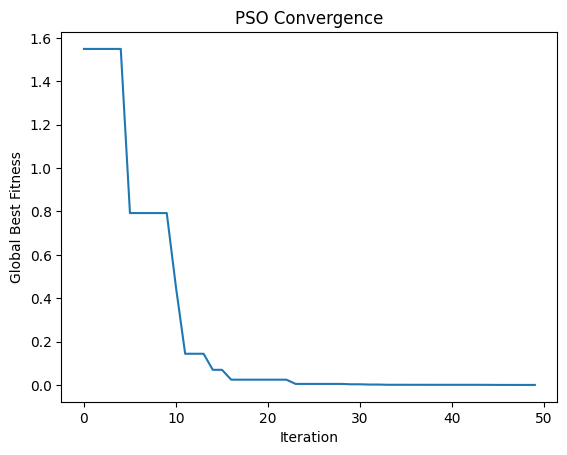

In [ ]:
plt.plot(history)

plt.xlabel("Iteration")
plt.ylabel("Global Best Fitness")
plt.title("PSO Convergence")

plt.show()